# Alkaline vs Carbonatite REE — Geophysical Similarity Test

**Goal**: Determine whether alkaline-hosted and carbonatite-hosted REE deposits are
indistinguishable in geophysical + proximity feature space.  
- **AUC ≈ 0.5** → two populations look the same → safe to merge as one positive class  
- **AUC >> 0.5** → systematically different → keep them separate

**Method** (mirrors the geochem PCA in `multiregion_rf_devnet.ipynb`, but with geophysical features):
1. Sample the same 17 national rasters + 6 proximity features at every deposit location  
2. Z-score normalise after median imputation  
3. PCA / MDS, coloured by host type *and* by study region (dual colouring to spot Cordilleran bias)  
4. Binary RF + LR classifier, spatial-block cross-validation → AUC

## 1. Imports & Paths

In [1]:
import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.metrics import roc_auc_score
import rasterio
import pyproj

BASE = '../dataset'
PROJECTED_CRS = 'EPSG:3978'   # Canada Atlas Lambert

# ── National rasters ──────────────────────────────────────────────────────
_RASTERS = {
    'gravity_ba':          f'{BASE}/converted getech data/Gravity_converted/Canada_BA.flt',
    'gravity_ba_1vd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_1VD.flt',
    'gravity_ba_hp100km':  f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP100km.flt',
    'gravity_ba_hp40km':   f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP40km.flt',
    'gravity_ba_thd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD.flt',
    'gravity_ba_thd_tilt': f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD_Tilt.flt',
    'mag_drtp':            f'{BASE}/converted getech data/Magnetic_converted/DRTP.flt',
    'mag_drtp_1vd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_1VD.flt',
    'mag_drtp_thd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD.flt',
    'mag_drtp_thd_tilt':   f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD_Tilt.flt',
    'mag_tmi':             f'{BASE}/converted getech data/Magnetic_converted/TMI.flt',
    'gravity_up30km':      f'{BASE}/new USGS data/GeophysicsGravity_Up30km_USCanada.tif',
    'gravity_up30km_hgm':  f'{BASE}/new USGS data/GeophysicsGravity_Up30km_HGM_USCanada.tif',
    'lab_depth':           f'{BASE}/new USGS data/GeophysicsLAB_USCanada.tif',
    'mag_rtp_deep':        f'{BASE}/new USGS data/USCanadaMagRTP_DeepSources.tif',
    'mag_rtp_hgm_deep':    f'{BASE}/new USGS data/USCanadaMagRTP_HGMDeepSources.tif',
    'moho_depth':          f'{BASE}/new USGS data/USCanada_Moho.tif',
}

FAULT_PATH   = f'{BASE}/Faults_Canada/Faults_Canada.geojson'
MARGIN_PATH  = f'{BASE}/Passive Margins/AncientPassiveMargins.geojson'
WORM_PATHS   = {
    'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
    'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
    'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
    'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
}
REGION_FILES = {
    'Cordilleran': f'{BASE}/3_areas/Cordilleran.geojson',
    'Superior':    f'{BASE}/3_areas/Superior.geojson',
    'Grenville':   f'{BASE}/3_areas/Grenville.geojson',
}

RANDOM_SEED = 42
print('Imports OK')

Imports OK


## 2. Load Deposits

In [2]:
carb_raw = pd.read_csv(f'{BASE}/REE_Canada/REE_Canada_Carbonatite.csv')
alk_raw  = pd.read_csv(f'{BASE}/REE_Canada/REE_Canada_Alkaline.csv')

carb = carb_raw.dropna(subset=['Latitude', 'Longitude']).copy()
alk  = alk_raw.dropna(subset=['Latitude', 'Longitude']).copy()

carb['host_type'] = 'Carbonatite'
alk['host_type']  = 'Alkaline'

# Combine
deps = pd.concat([carb[['Latitude','Longitude','host_type','State_Prov']],
                  alk [['Latitude','Longitude','host_type','State_Prov']]], ignore_index=True)
deps = deps.rename(columns={'Latitude':'lat','Longitude':'lon','State_Prov':'province'})

print(f'Carbonatite: {len(carb)}  |  Alkaline: {len(alk)}  |  Total: {len(deps)}')
deps.head()

Carbonatite: 61  |  Alkaline: 39  |  Total: 100


,lat,lon,host_type,province
0,49.9369,-75.8919,Carbonatite,Québec
1,52.1333,-119.1844,Carbonatite,British Columbia
2,56.4528,-123.7369,Carbonatite,British Columbia
3,56.4661,-123.7492,Carbonatite,British Columbia
4,50.7500,-81.0170,Carbonatite,Ontario


## 3. Assign Study Region & Dual-Colour Group

Each deposit gets a `region` label (Cordilleran / Superior / Grenville / Other).  
A `dual_group` combines host type and region for the dual-colouring scheme used to
visually detect Cordilleran mixing.

In [3]:
deps_gdf = gpd.GeoDataFrame(
    deps, geometry=gpd.points_from_xy(deps['lon'], deps['lat']), crs='EPSG:4326')

deps['region'] = 'Other'
for rname, rpath in REGION_FILES.items():
    bnd = gpd.read_file(rpath).to_crs('EPSG:4326')
    mask = deps_gdf.within(bnd.union_all())
    deps.loc[mask, 'region'] = rname

deps['dual_group'] = deps['host_type'] + ' / ' + deps['region']

print(deps.groupby(['host_type','region']).size().reset_index(name='n').to_string(index=False))

  host_type      region  n
   Alkaline Cordilleran  5
   Alkaline   Grenville 14
   Alkaline       Other 17
   Alkaline    Superior  3
Carbonatite Cordilleran 43
Carbonatite   Grenville  6
Carbonatite       Other  4
Carbonatite    Superior  8


## 4. Helper Functions

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))


def normalize_proximity(dist_arr):
    dmin, dmax = dist_arr.min(), dist_arr.max()
    if dmax > dmin:
        return 1.0 - (dist_arr - dmin) / (dmax - dmin)
    return np.zeros_like(dist_arr, dtype=float)


def sample_raster_at_points(raster_path, lats, lons):
    """Sample a raster at arbitrary lat/lon points without loading the whole array."""
    vals = np.full(len(lats), np.nan)
    if not os.path.exists(raster_path):
        return vals
    try:
        with rasterio.open(raster_path) as src:
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(lons, lats)
            else:
                xs, ys = np.array(lons), np.array(lats)
            nd = src.nodata
            for i, (xi, yi) in enumerate(zip(xs, ys)):
                try:
                    row, col = src.index(xi, yi)
                    if 0 <= row < src.height and 0 <= col < src.width:
                        v = src.read(1, window=rasterio.windows.Window(col, row, 1, 1))[0, 0]
                        if nd is None or v != nd:
                            vals[i] = float(v)
                except Exception:
                    pass
    except Exception as e:
        print(f'  Warning: could not read {raster_path}: {e}')
    return vals


def add_proximity_lines(pts_df, geojson_path, col_prefix):
    gdf = gpd.read_file(geojson_path).to_crs(PROJECTED_CRS)
    su  = gdf.geometry.union_all()
    g   = gpd.GeoDataFrame(
            pts_df.copy(),
            geometry=gpd.points_from_xy(pts_df['lon'], pts_df['lat']),
            crs='EPSG:4326').to_crs(PROJECTED_CRS)
    dist = g.geometry.apply(lambda p: p.distance(su)).values.astype(float)
    pts_df = pts_df.copy()
    pts_df[f'{col_prefix}_dist_m']    = dist
    pts_df[f'{col_prefix}_proximity'] = normalize_proximity(dist)
    return pts_df


def build_worm_trees(worm_paths):
    trees = {}
    for name, path in worm_paths.items():
        print(f'  loading worms: {name} ...')
        w = gpd.read_file(path).to_crs(PROJECTED_CRS)
        coords = np.column_stack([w.geometry.x, w.geometry.y])
        trees[name] = cKDTree(coords)
    return trees


def add_proximity_worms(pts_df, worm_trees):
    g = gpd.GeoDataFrame(
            pts_df.copy(),
            geometry=gpd.points_from_xy(pts_df['lon'], pts_df['lat']),
            crs='EPSG:4326').to_crs(PROJECTED_CRS)
    coords = np.column_stack([g.geometry.x, g.geometry.y])
    pts_df = pts_df.copy()
    for name, tree in worm_trees.items():
        dist, _ = tree.query(coords, k=1)
        pts_df[f'worm_{name}_dist_m']    = dist.astype(float)
        pts_df[f'worm_{name}_proximity'] = normalize_proximity(dist.astype(float))
    return pts_df


print('Helpers defined.')

Helpers defined.


## 5. Extract Features

In [5]:
# ── 5a. Raster values ──────────────────────────────────────────────────────
print('Sampling rasters ...')
lats = deps['lat'].values
lons = deps['lon'].values

for feat, path in _RASTERS.items():
    print(f'  {feat} ...', end=' ')
    deps[feat] = sample_raster_at_points(path, lats, lons)
    n_valid = deps[feat].notna().sum()
    print(f'{n_valid}/{len(deps)} valid')

RASTER_COLS = list(_RASTERS.keys())
print(f'\n{len(RASTER_COLS)} rasters extracted.')

Sampling rasters ...
  gravity_ba ... 100/100 valid
  gravity_ba_1vd ... 100/100 valid
  gravity_ba_hp100km ... 100/100 valid
  gravity_ba_hp40km ... 100/100 valid
  gravity_ba_thd ... 100/100 valid
  gravity_ba_thd_tilt ... 100/100 valid
  mag_drtp ... 100/100 valid
  mag_drtp_1vd ... 100/100 valid
  mag_drtp_thd ... 100/100 valid
  mag_drtp_thd_tilt ... 100/100 valid
  mag_tmi ... 100/100 valid
  gravity_up30km ... 100/100 valid
  gravity_up30km_hgm ... 100/100 valid
  lab_depth ... 99/100 valid
  mag_rtp_deep ... 99/100 valid
  mag_rtp_hgm_deep ... 100/100 valid
  moho_depth ... 100/100 valid

17 rasters extracted.


In [6]:
# ── 5b. Fault + margin proximity ───────────────────────────────────────────
print('Computing fault proximity ...')
deps = add_proximity_lines(deps, FAULT_PATH,  'fault')
print('Computing passive margin proximity ...')
deps = add_proximity_lines(deps, MARGIN_PATH, 'margin')
print('Done.')

Computing fault proximity ...
Computing passive margin proximity ...
Done.


In [7]:
# ── 5c. Worm proximity ─────────────────────────────────────────────────────
print('Building worm KDTrees ...')
WORM_TREES = build_worm_trees(WORM_PATHS)
deps = add_proximity_worms(deps, WORM_TREES)
print('Worm proximity computed.')

Building worm KDTrees ...
  loading worms: shallow_grav ...
  loading worms: deep_grav ...
  loading worms: shallow_mag ...
  loading worms: deep_mag ...
Worm proximity computed.


## 6. Feature Matrix + Z-Score Normalisation

In [8]:
PROXIMITY_COLS = [
    'fault_proximity', 'margin_proximity',
    'worm_shallow_grav_proximity', 'worm_deep_grav_proximity',
    'worm_shallow_mag_proximity',  'worm_deep_mag_proximity',
]

ALL_FEAT_COLS = PROXIMITY_COLS + RASTER_COLS
feat_cols = [c for c in ALL_FEAT_COLS if c in deps.columns]

X_raw = deps[feat_cols].astype(float).values

# Median imputation → Z-score
imputer = SimpleImputer(strategy='median')
scaler  = StandardScaler()
X_imp   = imputer.fit_transform(X_raw)
X       = scaler.fit_transform(X_imp)

host  = deps['host_type'].values          # 'Carbonatite' | 'Alkaline'
y     = (host == 'Alkaline').astype(int)  # 0=Carbonatite, 1=Alkaline
region = deps['region'].values

n_nan_rows = np.isnan(X_raw).all(axis=1).sum()
print(f'Feature matrix: {X.shape}  |  {n_nan_rows} rows with ALL features NaN')
print(f'Host types — Carbonatite: {(y==0).sum()}  Alkaline: {(y==1).sum()}')
print(f'Features: {feat_cols}')

Feature matrix: (100, 23)  |  0 rows with ALL features NaN
Host types — Carbonatite: 61  Alkaline: 39
Features: ['fault_proximity', 'margin_proximity', 'worm_shallow_grav_proximity', 'worm_deep_grav_proximity', 'worm_shallow_mag_proximity', 'worm_deep_mag_proximity', 'gravity_ba', 'gravity_ba_1vd', 'gravity_ba_hp100km', 'gravity_ba_hp40km', 'gravity_ba_thd', 'gravity_ba_thd_tilt', 'mag_drtp', 'mag_drtp_1vd', 'mag_drtp_thd', 'mag_drtp_thd_tilt', 'mag_tmi', 'gravity_up30km', 'gravity_up30km_hgm', 'lab_depth', 'mag_rtp_deep', 'mag_rtp_hgm_deep', 'moho_depth']


## 7. PCA — Coloured by Host Type

First panel: host type only.  
Second panel: dual colouring (host type × region) to flag Cordilleran-specific clustering.

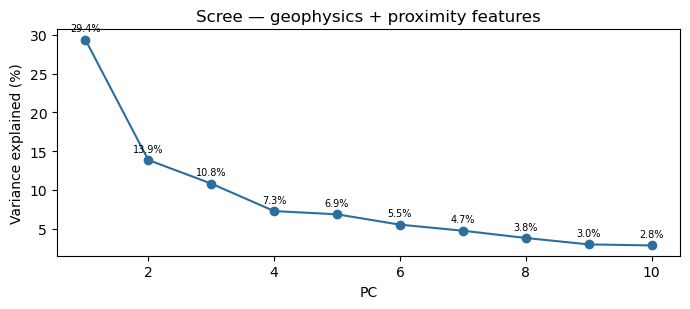

PC1=29.4%  PC2=13.9%  PC3=10.8%


In [9]:
pca = PCA(n_components=min(10, X.shape[1])).fit(X)
sc  = pca.transform(X)
var = pca.explained_variance_ratio_

# ── Scree ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(1, len(var)+1), var*100, 'o-', color='#2c6e9e')
for i, v in enumerate(var, 1):
    ax.annotate(f'{v*100:.1f}%', (i, v*100), textcoords='offset points',
                xytext=(0, 6), fontsize=7, ha='center')
ax.set_xlabel('PC'); ax.set_ylabel('Variance explained (%)')
ax.set_title('Scree — geophysics + proximity features')
plt.tight_layout(); plt.show()
print('PC1={:.1f}%  PC2={:.1f}%  PC3={:.1f}%'.format(*[v*100 for v in var[:3]]))

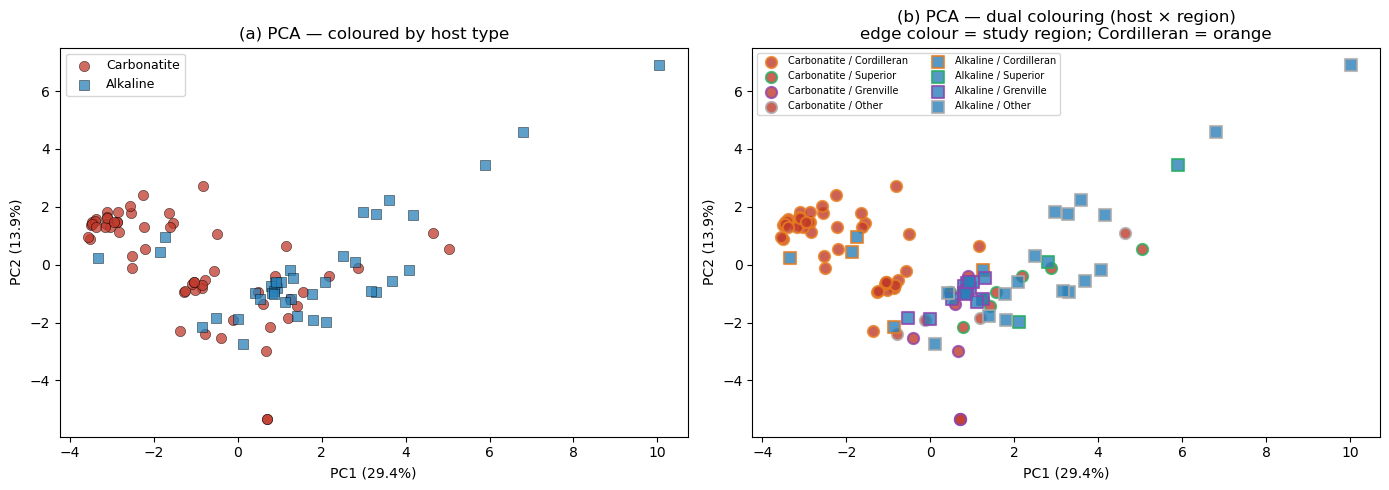

Saved pca_alkaline_vs_carbonatite.png


In [10]:
# ── Panel A: host-type colouring ─────────────────────────────────────────────
HOST_PALETTE = {'Carbonatite': '#c0392b', 'Alkaline': '#2980b9'}
HOST_MARKER  = {'Carbonatite': 'o',       'Alkaline': 's'}

REGION_EDGE  = {'Cordilleran': '#e67e22', 'Superior': '#27ae60',
                'Grenville': '#8e44ad',   'Other': '#aaaaaa'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ─ left: host type only ─
ax = axes[0]
for ht, col in HOST_PALETTE.items():
    m = host == ht
    ax.scatter(sc[m, 0], sc[m, 1], c=col, marker=HOST_MARKER[ht],
               s=55, alpha=0.75, edgecolors='k', linewidths=0.4, label=ht)
ax.set_xlabel(f'PC1 ({var[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
ax.set_title('(a) PCA — coloured by host type')
ax.legend(fontsize=9)

# ─ right: dual colouring — host type fills, region edge colour ─
ax = axes[1]
for ht, fcol in HOST_PALETTE.items():
    for reg, ecol in REGION_EDGE.items():
        m = (host == ht) & (region == reg)
        if m.sum() == 0:
            continue
        ax.scatter(sc[m, 0], sc[m, 1], facecolor=fcol, edgecolors=ecol,
                   marker=HOST_MARKER[ht], s=65, alpha=0.80,
                   linewidths=1.5, label=f'{ht} / {reg}')
ax.set_xlabel(f'PC1 ({var[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
ax.set_title('(b) PCA — dual colouring (host × region)\n'
             'edge colour = study region; Cordilleran = orange')
ax.legend(fontsize=7, loc='best', ncol=2)

plt.tight_layout()
plt.savefig('pca_alkaline_vs_carbonatite.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved pca_alkaline_vs_carbonatite.png')

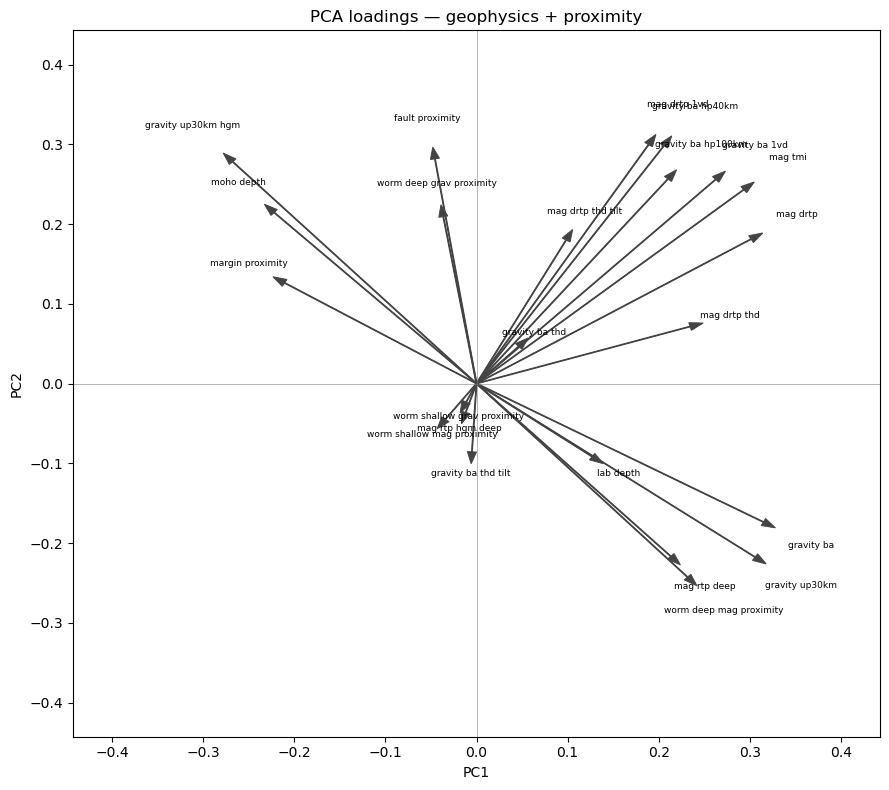

In [11]:
# ── PCA biplot (loadings) ─────────────────────────────────────────────────────
comp = pca.components_
fig, ax = plt.subplots(figsize=(9, 8))
lim = np.abs(comp[:2]).max() * 1.35
for j, c in enumerate(feat_cols):
    ax.arrow(0, 0, comp[0, j], comp[1, j],
             head_width=0.01, color='#444', lw=0.7, length_includes_head=True)
    ax.text(comp[0, j]*1.12, comp[1, j]*1.12, c.replace('_', ' '),
            fontsize=6.5, ha='center', va='center')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('PCA loadings — geophysics + proximity')
plt.tight_layout(); plt.show()

## 8. MDS (metric, 2-D)

Running MDS (this may take ~30 s for large n) ...
MDS stress: 13479.8794


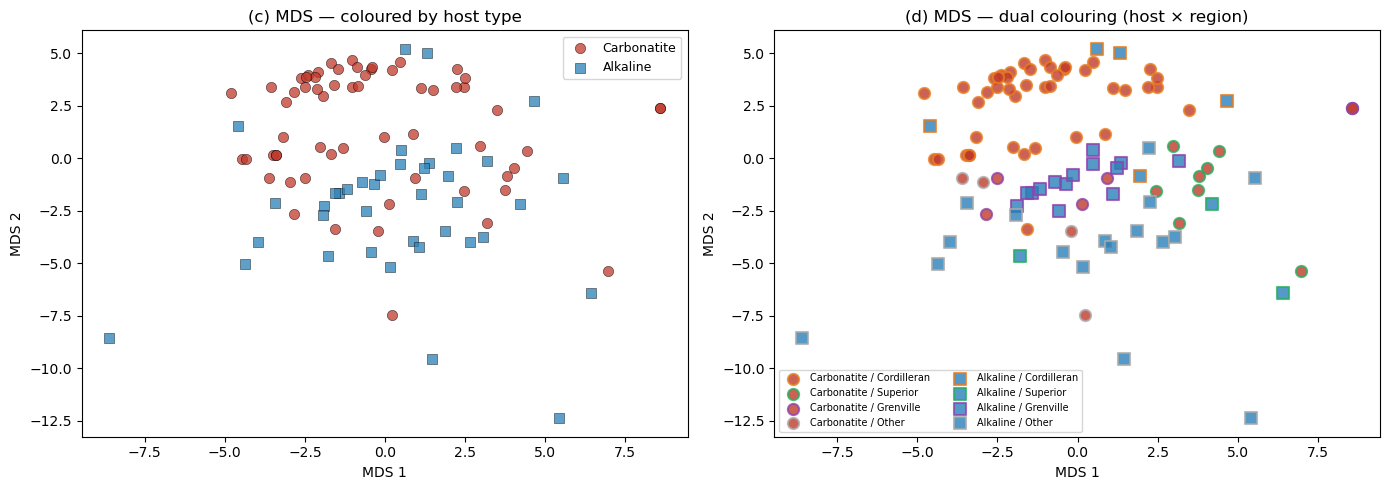

In [12]:
print('Running MDS (this may take ~30 s for large n) ...')
mds = MDS(n_components=2, metric=True, random_state=RANDOM_SEED, n_init=4, max_iter=500)
X_mds = mds.fit_transform(X)
print(f'MDS stress: {mds.stress_:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for ht, col in HOST_PALETTE.items():
    m = host == ht
    ax.scatter(X_mds[m, 0], X_mds[m, 1], c=col, marker=HOST_MARKER[ht],
               s=55, alpha=0.75, edgecolors='k', linewidths=0.4, label=ht)
ax.set_xlabel('MDS 1'); ax.set_ylabel('MDS 2')
ax.set_title('(c) MDS — coloured by host type')
ax.legend(fontsize=9)

ax = axes[1]
for ht, fcol in HOST_PALETTE.items():
    for reg, ecol in REGION_EDGE.items():
        m = (host == ht) & (region == reg)
        if m.sum() == 0:
            continue
        ax.scatter(X_mds[m, 0], X_mds[m, 1], facecolor=fcol, edgecolors=ecol,
                   marker=HOST_MARKER[ht], s=65, alpha=0.80,
                   linewidths=1.5, label=f'{ht} / {reg}')
ax.set_xlabel('MDS 1'); ax.set_ylabel('MDS 2')
ax.set_title('(d) MDS — dual colouring (host × region)')
ax.legend(fontsize=7, loc='best', ncol=2)

plt.tight_layout()
plt.savefig('mds_alkaline_vs_carbonatite.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. PC1 / PC2 Density — Carbonatite vs Alkaline

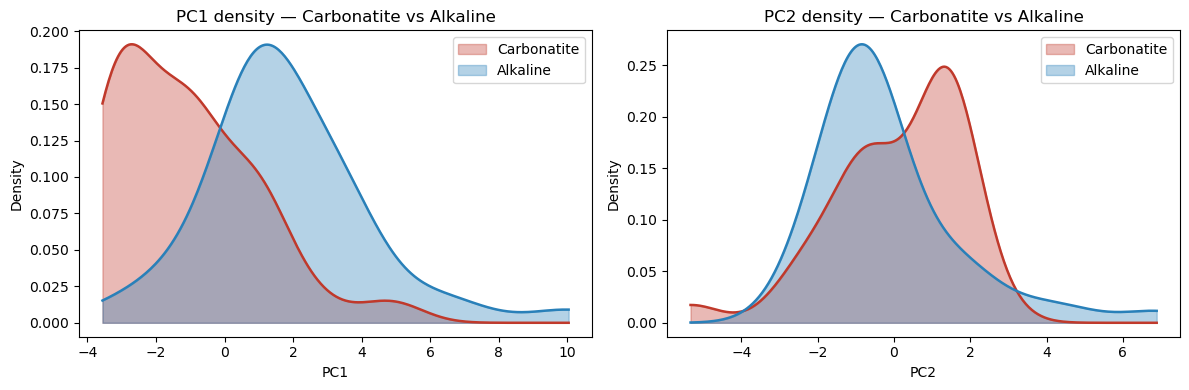

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax_i, (pc_idx, pc_lbl) in enumerate([(0,'PC1'), (1,'PC2')]):
    ax = axes[ax_i]
    grid = np.linspace(sc[:, pc_idx].min(), sc[:, pc_idx].max(), 300)
    for ht, col in HOST_PALETTE.items():
        m = host == ht
        if m.sum() > 1:
            ax.fill_between(grid, gaussian_kde(sc[m, pc_idx])(grid),
                            alpha=0.35, color=col, label=ht)
            ax.plot(grid, gaussian_kde(sc[m, pc_idx])(grid), color=col, lw=1.8)
    ax.set_xlabel(pc_lbl); ax.set_ylabel('Density')
    ax.set_title(f'{pc_lbl} density — Carbonatite vs Alkaline')
    ax.legend()
plt.tight_layout(); plt.show()

## 10. Binary Classifier — Spatial Block Cross-Validation

Spatial blocking: 4 ° × 4 ° longitude–latitude tiles.  
Leave-One-Group-Out (LOGO) ensures spatially separated test folds — avoids
inflated AUC from spatial autocorrelation.  
Classifiers: **RandomForest** (non-linear) and **LogisticRegression** (linear baseline).

**Interpretation**
| AUC | Conclusion |
|-----|------------|
| ≈ 0.5 | Two host types are geophysically indistinguishable → safe to merge |
| 0.6–0.7 | Moderate separation → merge with caution |
| > 0.7 | Clear separation → do **not** merge |

In [14]:
# ── Spatial blocks ────────────────────────────────────────────────────────────
BLOCK_DEG = 4.0
deps['block_lat'] = (deps['lat'] // BLOCK_DEG).astype(int)
deps['block_lon'] = (deps['lon'] // BLOCK_DEG).astype(int)
deps['spatial_block'] = deps['block_lat'].astype(str) + '_' + deps['block_lon'].astype(str)

groups = deps['spatial_block'].values
unique_blocks = np.unique(groups)
print(f'Spatial blocks: {len(unique_blocks)}')
print(pd.Series(groups).value_counts().head(15).to_string())

Spatial blocks: 26
13_-30    22
13_-16    17
12_-30    11
13_-31     5
15_-29     5
11_-20     4
11_-19     3
12_-22     3
12_-19     3
12_-20     3
11_-17     2
13_-24     2
12_-21     2
14_-31     2
13_-32     2


In [15]:
# ── Remove blocks that contain only one class (LOGO requires both classes in train) ──
valid_mask = np.ones(len(deps), dtype=bool)
for blk in unique_blocks:
    idx = np.where(groups == blk)[0]
    if len(np.unique(y[idx])) < 2:
        # Keep for prediction but mark block as non-scoreable in LOGO
        pass  # handled implicitly — LOGO skips folds where test only has one class

logo = LeaveOneGroupOut()

def spatial_cv_auc(clf, X_, y_, groups_):
    aucs = []
    for train_idx, test_idx in logo.split(X_, y_, groups_):
        y_train = y_[train_idx]
        if len(np.unique(y_train)) < 2:
            continue   # can't train without both classes
        y_test = y_[test_idx]
        if len(np.unique(y_test)) < 2:
            continue   # can't score AUC with one class in test
        clf.fit(X_[train_idx], y_train)
        if hasattr(clf, 'predict_proba'):
            prob = clf.predict_proba(X_[test_idx])[:, 1]
        else:
            prob = clf.decision_function(X_[test_idx])
        aucs.append(roc_auc_score(y_test, prob))
    return np.array(aucs)

np.random.seed(RANDOM_SEED)
clf_rf = RandomForestClassifier(n_estimators=300, max_features='sqrt',
                                class_weight='balanced', random_state=RANDOM_SEED)
clf_lr = LogisticRegression(max_iter=1000, class_weight='balanced',
                            random_state=RANDOM_SEED, C=0.1)

print('Running LOGO spatial CV ...')
aucs_rf = spatial_cv_auc(clf_rf, X, y, groups)
aucs_lr = spatial_cv_auc(clf_lr, X, y, groups)

print(f'\nRandom Forest  — AUC folds: {aucs_rf.round(3)}  →  mean={aucs_rf.mean():.3f} ± {aucs_rf.std():.3f}')
print(f'Logistic Regr  — AUC folds: {aucs_lr.round(3)}  →  mean={aucs_lr.mean():.3f} ± {aucs_lr.std():.3f}')
print()
if aucs_rf.mean() < 0.60:
    print('>>> AUC ≈ 0.5 — the two host types are GEOPHYSICALLY INDISTINGUISHABLE → safe to merge.')
elif aucs_rf.mean() < 0.70:
    print('>>> AUC 0.6–0.7 — MODERATE separation → merge with caution; re-check after excluding Cordilleran.')
else:
    print('>>> AUC > 0.7 — CLEAR separation → do NOT merge; keep as separate positive classes.')

Running LOGO spatial CV ...

Random Forest  — AUC folds: [1.    0.    1.    1.    0.125 1.    1.   ]  →  mean=0.732 ± 0.425
Logistic Regr  — AUC folds: [1.    0.5   1.    1.    0.125 1.    1.   ]  →  mean=0.804 ± 0.326

>>> AUC > 0.7 — CLEAR separation → do NOT merge; keep as separate positive classes.


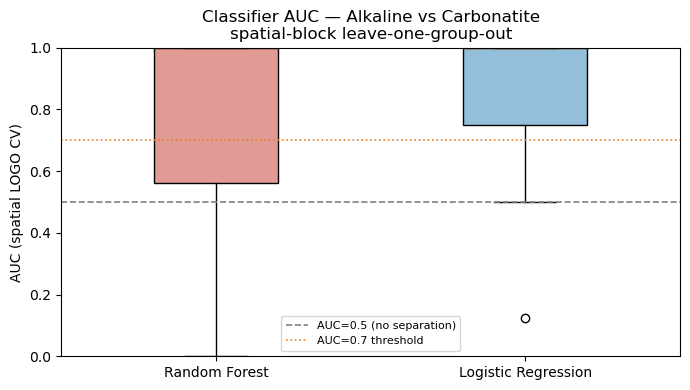

RF AUC: 0.732 ± 0.425   |   LR AUC: 0.804 ± 0.326


In [16]:
# ── AUC boxplot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot([aucs_rf, aucs_lr], labels=['Random Forest', 'Logistic Regression'],
                patch_artist=True, widths=0.4)
bp['boxes'][0].set_facecolor('#c0392b80')
bp['boxes'][1].set_facecolor('#2980b980')
ax.axhline(0.5, ls='--', color='grey', lw=1.2, label='AUC=0.5 (no separation)')
ax.axhline(0.7, ls=':', color='#e67e22', lw=1.2, label='AUC=0.7 threshold')
ax.set_ylabel('AUC (spatial LOGO CV)')
ax.set_title('Classifier AUC — Alkaline vs Carbonatite\n'
             'spatial-block leave-one-group-out')
ax.legend(fontsize=8)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('auc_alkaline_vs_carbonatite.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'RF AUC: {aucs_rf.mean():.3f} ± {aucs_rf.std():.3f}   |   LR AUC: {aucs_lr.mean():.3f} ± {aucs_lr.std():.3f}')

## 11. Repeat Without Cordilleran — Sensitivity Check

Cordilleran has a strong Carbonatite bias (41 of 61 carbonatite deposits sit there).  
Dropping those points tests whether any AUC signal is purely a regional artefact.

In [17]:
no_cord_mask = (region != 'Cordilleran')
X_nc   = X[no_cord_mask]
y_nc   = y[no_cord_mask]
g_nc   = groups[no_cord_mask]
host_nc = host[no_cord_mask]

print(f'After removing Cordilleran: {no_cord_mask.sum()} points')
print(f'  Carbonatite: {(y_nc==0).sum()}  |  Alkaline: {(y_nc==1).sum()}')

# Refit scaler/imputer on the reduced set
X_raw_nc = deps.loc[no_cord_mask, feat_cols].astype(float).values
imp_nc = SimpleImputer(strategy='median')
sc_nc  = StandardScaler()
X_nc   = sc_nc.fit_transform(imp_nc.fit_transform(X_raw_nc))

aucs_rf_nc = spatial_cv_auc(
    RandomForestClassifier(n_estimators=300, max_features='sqrt',
                           class_weight='balanced', random_state=RANDOM_SEED),
    X_nc, y_nc, g_nc)
aucs_lr_nc = spatial_cv_auc(
    LogisticRegression(max_iter=1000, class_weight='balanced',
                       random_state=RANDOM_SEED, C=0.1),
    X_nc, y_nc, g_nc)

print(f'\n[No Cordilleran] RF AUC: {aucs_rf_nc.mean():.3f} ± {aucs_rf_nc.std():.3f}')
print(f'[No Cordilleran] LR AUC: {aucs_lr_nc.mean():.3f} ± {aucs_lr_nc.std():.3f}')

After removing Cordilleran: 52 points
  Carbonatite: 18  |  Alkaline: 34

[No Cordilleran] RF AUC: 0.917 ± 0.186
[No Cordilleran] LR AUC: 0.750 ± 0.382


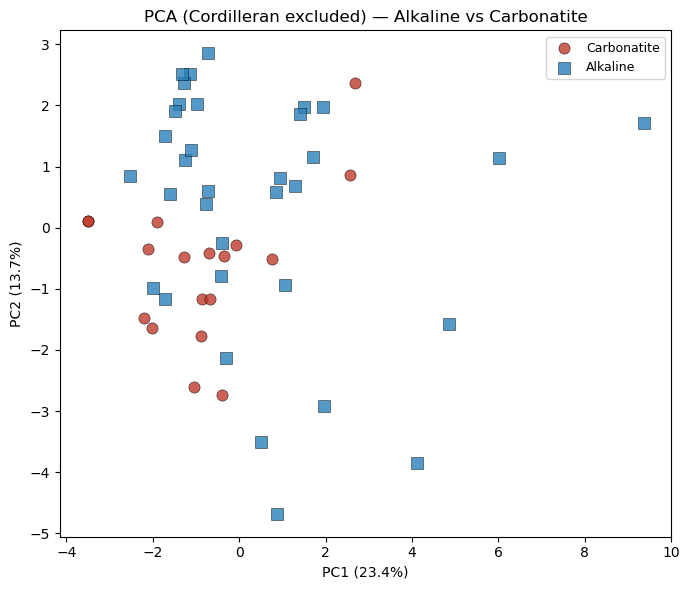

In [18]:
# ── PCA without Cordilleran ───────────────────────────────────────────────────
pca_nc = PCA(n_components=min(6, X_nc.shape[1])).fit(X_nc)
sc2    = pca_nc.transform(X_nc)
var_nc = pca_nc.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 6))
for ht, col in HOST_PALETTE.items():
    m = host_nc == ht
    ax.scatter(sc2[m, 0], sc2[m, 1], c=col, marker=HOST_MARKER[ht],
               s=65, alpha=0.8, edgecolors='k', linewidths=0.4, label=ht)
ax.set_xlabel(f'PC1 ({var_nc[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({var_nc[1]*100:.1f}%)')
ax.set_title('PCA (Cordilleran excluded) — Alkaline vs Carbonatite')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('pca_no_cordilleran.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Feature Importance (RF, full dataset)

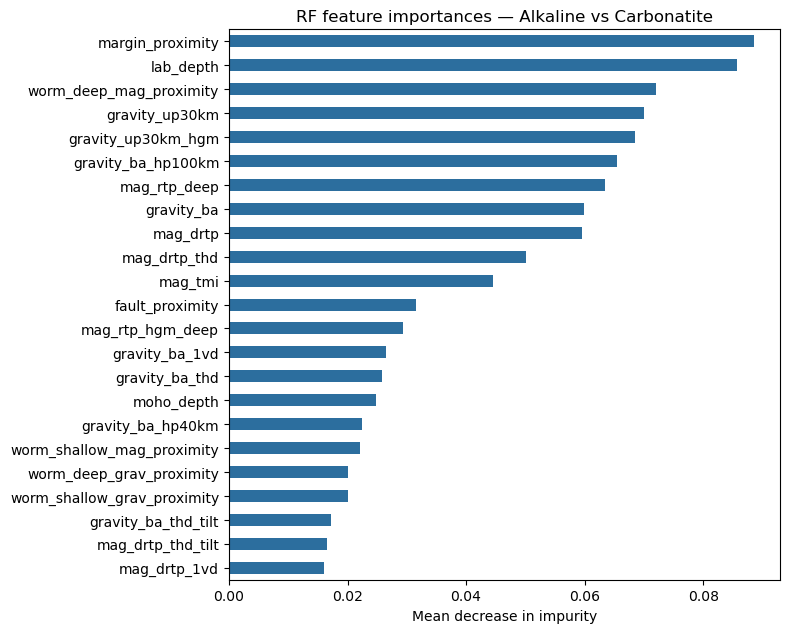

In [19]:
rf_full = RandomForestClassifier(n_estimators=500, max_features='sqrt',
                                 class_weight='balanced', random_state=RANDOM_SEED)
rf_full.fit(X, y)
importances = pd.Series(rf_full.feature_importances_, index=feat_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, max(5, len(feat_cols)*0.28)))
importances.plot.barh(ax=ax, color='#2c6e9e')
ax.set_xlabel('Mean decrease in impurity')
ax.set_title('RF feature importances — Alkaline vs Carbonatite')
plt.tight_layout()
plt.savefig('rf_importance_alkaline_carbonatite.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Summary

In [20]:
print('='*60)
print('ALKALINE vs CARBONATITE — GEOPHYSICAL SIMILARITY REPORT')
print('='*60)
print(f'Total deposits: {len(deps)}  (Carb={( y==0).sum()}, Alk={( y==1).sum()})')
print(f'Features used : {len(feat_cols)}')
print()
print('--- FULL DATASET ---')
print(f'  RF  AUC (spatial LOGO): {aucs_rf.mean():.3f} ± {aucs_rf.std():.3f}  (n_folds={len(aucs_rf)})')
print(f'  LR  AUC (spatial LOGO): {aucs_lr.mean():.3f} ± {aucs_lr.std():.3f}  (n_folds={len(aucs_lr)})')
print()
print('--- CORDILLERAN EXCLUDED ---')
print(f'  RF  AUC (spatial LOGO): {aucs_rf_nc.mean():.3f} ± {aucs_rf_nc.std():.3f}  (n_folds={len(aucs_rf_nc)})')
print(f'  LR  AUC (spatial LOGO): {aucs_lr_nc.mean():.3f} ± {aucs_lr_nc.std():.3f}  (n_folds={len(aucs_lr_nc)})')
print()
rf_auc = max(aucs_rf.mean(), aucs_rf_nc.mean())
if rf_auc < 0.60:
    verdict = 'MERGE — populations are geophysically indistinguishable.'
elif rf_auc < 0.70:
    verdict = 'MERGE WITH CAUTION — moderate separation, investigate Cordilleran bias.'
else:
    verdict = 'DO NOT MERGE — clear geophysical separation between host types.'
print(f'VERDICT: {verdict}')
print('='*60)

ALKALINE vs CARBONATITE — GEOPHYSICAL SIMILARITY REPORT
Total deposits: 100  (Carb=61, Alk=39)
Features used : 23

--- FULL DATASET ---
  RF  AUC (spatial LOGO): 0.732 ± 0.425  (n_folds=7)
  LR  AUC (spatial LOGO): 0.804 ± 0.326  (n_folds=7)

--- CORDILLERAN EXCLUDED ---
  RF  AUC (spatial LOGO): 0.917 ± 0.186  (n_folds=6)
  LR  AUC (spatial LOGO): 0.750 ± 0.382  (n_folds=6)

VERDICT: DO NOT MERGE — clear geophysical separation between host types.
